In [ ]:
!nvidia-smi

import tensorflow as tf
print("GPU:", tf.config.list_physical_devices("GPU"))

Fri Nov 20 05:17:59 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!git clone https://github.com/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset.git

Cloning into 'Traditional-Chinese-Handwriting-Dataset'...
remote: Enumerating objects: 174, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 174 (delta 5), reused 1 (delta 1), pack-reused 167 (from 1)
Receiving objects: 100% (174/174), 77.40 MiB | 26.61 MiB/s, done.
Resolving deltas: 100% (78/78), done.


In [ ]:
from pathlib import Path

root = Path("/content/Traditional-Chinese-Handwriting-Dataset")

files = sorted(p for p in root.rglob("*") if p.is_file())

for p in files[:60]:
    print(p.relative_to(root))

.git/HEAD
.git/config
.git/description
.git/hooks/applypatch-msg.sample
.git/hooks/commit-msg.sample
.git/hooks/fsmonitor-watchman.sample
.git/hooks/post-update.sample
.git/hooks/pre-applypatch.sample
.git/hooks/pre-commit.sample
.git/hooks/pre-merge-commit.sample
.git/hooks/pre-push.sample
.git/hooks/pre-rebase.sample
.git/hooks/pre-receive.sample
.git/hooks/prepare-commit-msg.sample
.git/hooks/push-to-checkout.sample
.git/hooks/sendemail-validate.sample
.git/hooks/update.sample
.git/index
.git/info/exclude
.git/logs/HEAD
.git/logs/refs/heads/master
.git/logs/refs/remotes/origin/HEAD
.git/objects/pack/pack-049d119ad0eb70c7f75eb996846aa932acc89f8f.idx
.git/objects/pack/pack-049d119ad0eb70c7f75eb996846aa932acc89f8f.pack
.git/objects/pack/pack-049d119ad0eb70c7f75eb996846aa932acc89f8f.rev
.git/packed-refs
.git/refs/heads/master
.git/refs/remotes/origin/HEAD
Data_Deployment_colab.ipynb
Data_Deployment_local.ipynb
License
README.md
data/cleaned_data(50_50)-20200420T071507Z-001.zip
data/clea

In [ ]:
from pathlib import Path
import zipfile

root = Path("/content/Traditional-Chinese-Handwriting-Dataset")
zip_paths = sorted((root / "data").glob("*.zip"))

print("Number of ZIP files:", len(zip_paths))

if not zip_paths:
    raise FileNotFoundError(
        "No ZIP files found. Please check the dataset directory."
    )

total_files = 0
total_bytes = 0

for zip_path in zip_paths:
    print("\n" + "=" * 60)
    print("Archive:", zip_path.name)

    if not zipfile.is_zipfile(zip_path):
        raise ValueError(f"Invalid ZIP file: {zip_path.name}")

    with zipfile.ZipFile(zip_path) as archive:
        entries = [
            item for item in archive.infolist()
            if not item.is_dir()
        ]

        total_files += len(entries)
        total_bytes += sum(item.file_size for item in entries)

        print("Number of files:", len(entries))
        print("First 8 file paths:")

        for item in entries[:8]:
            print(" ", item.filename)

print("\n" + "=" * 60)
print("Total file entries across archives:", total_files)
print(f"Total uncompressed size: {total_bytes / 1024**3:.2f} GB")

Number of ZIP files: 4

Archive: cleaned_data(50_50)-20200420T071507Z-001.zip
Number of files: 65535
First 8 file paths:
  cleaned_data(50_50)/齷_42.png
  cleaned_data(50_50)/齷_48.png
  cleaned_data(50_50)/齷_37.png
  cleaned_data(50_50)/齷_45.png
  cleaned_data(50_50)/齷_32.png
  cleaned_data(50_50)/齷_47.png
  cleaned_data(50_50)/齷_31.png
  cleaned_data(50_50)/齷_46.png

Archive: cleaned_data(50_50)-20200420T071507Z-002.zip
Number of files: 65535
First 8 file paths:
  cleaned_data(50_50)/蟀_3.png
  cleaned_data(50_50)/螻_20.png
  cleaned_data(50_50)/螻_26.png
  cleaned_data(50_50)/貝_21.png
  cleaned_data(50_50)/螺_33.png
  cleaned_data(50_50)/蟀_22.png
  cleaned_data(50_50)/蟑_16.png
  cleaned_data(50_50)/螳_29.png

Archive: cleaned_data(50_50)-20200420T071507Z-003.zip
Number of files: 65535
First 8 file paths:
  cleaned_data(50_50)/澧_37.png
  cleaned_data(50_50)/澗_38.png
  cleaned_data(50_50)/澧_8.png
  cleaned_data(50_50)/澤_42.png
  cleaned_data(50_50)/澱_34.png
  cleaned_data(50_50)/瀑_49.png
  c

In [ ]:
from pathlib import Path, PurePosixPath
from collections import defaultdict, Counter
from PIL import Image
import re
import zipfile

root = Path("/content/Traditional-Chinese-Handwriting-Dataset")
zip_paths = sorted((root / "data").glob("*.zip"))

if not zip_paths:
    raise FileNotFoundError("No ZIP files found.")

samples_by_character = defaultdict(dict)
invalid_names = []
duplicate_keys = []
image_info = []

for zip_path in zip_paths:
    with zipfile.ZipFile(zip_path) as archive:
        preview_checked = False

        for entry in archive.infolist():
            if entry.is_dir():
                continue

            path = PurePosixPath(entry.filename)

            if "__MACOSX" in path.parts or path.name.startswith("._"):
                continue

            if path.suffix.lower() != ".png":
                continue

            match = re.fullmatch(r"(.+)_(\d+)", path.stem)

            if match is None:
                invalid_names.append(entry.filename)
                continue

            character = match.group(1)
            sample_number = int(match.group(2))

            record = {
                "archive": str(zip_path),
                "member": entry.filename,
                "sample_number": sample_number,
            }

            if sample_number in samples_by_character[character]:
                duplicate_keys.append((character, sample_number))
            else:
                samples_by_character[character][sample_number] = record

            if not preview_checked:
                with archive.open(entry) as file:
                    with Image.open(file) as image:
                        image_info.append({
                            "archive": zip_path.name,
                            "size": image.size,
                            "mode": image.mode,
                        })
                preview_checked = True

counts = {
    character: len(samples)
    for character, samples in samples_by_character.items()
}

if not counts:
    raise RuntimeError("No matching image filenames found.")

count_distribution = Counter(counts.values())

print("=== Dataset summary ===")
print("Unique characters:", len(counts))
print("Unique character/sample pairs:", sum(counts.values()))
print("Minimum samples per character:", min(counts.values()))
print("Maximum samples per character:", max(counts.values()))
print("Average samples per character:", round(
    sum(counts.values()) / len(counts), 2
))
print("Characters with fewer than 40 samples:",
      sum(count < 40 for count in counts.values()))
print("Characters with exactly 40 samples:",
      sum(count == 40 for count in counts.values()))
print("Duplicate character/sample pairs:", len(duplicate_keys))
print("Unrecognized PNG filenames:", len(invalid_names))

print("\n=== Sample count distribution ===")
print("Samples per character -> Number of characters")
for sample_count, character_count in sorted(count_distribution.items()):
    print(f"{sample_count} -> {character_count}")

print("\n=== Sample numbers for first 5 characters ===")
for character in sorted(samples_by_character)[:5]:
    print(repr(character), sorted(samples_by_character[character]))

print("\n=== Image properties: one image per archive ===")
for info in image_info:
    print(info)

if invalid_names:
    print("\nUnrecognized filename examples:", invalid_names[:5])

if duplicate_keys:
    print("\nDuplicate examples:", duplicate_keys[:5])

print("\n=== Assignment class-count check ===")
if len(counts) == 13065:
    print("PASS: Found 13,065 unique characters.")
else:
    print(
        f"CHECK REQUIRED: Found {len(counts):,} unique characters; "
        "the assignment specifies 13,065."
    )

=== Dataset summary ===
Unique characters: 4803
Unique character/sample pairs: 250712
Minimum samples per character: 16
Maximum samples per character: 61
Average samples per character: 52.2
Characters with fewer than 40 samples: 16
Characters with exactly 40 samples: 0
Duplicate character/sample pairs: 0
Unrecognized PNG filenames: 0

=== Sample count distribution ===
Samples per character -> Number of characters
16 -> 1
17 -> 1
20 -> 1
22 -> 1
31 -> 2
32 -> 4
34 -> 3
35 -> 2
36 -> 1
48 -> 2
49 -> 586
50 -> 1141
51 -> 1810
52 -> 178
53 -> 25
56 -> 2
57 -> 38
58 -> 313
59 -> 465
60 -> 226
61 -> 1

=== Sample numbers for first 5 characters ===
'丁' [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50]
'七' [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 

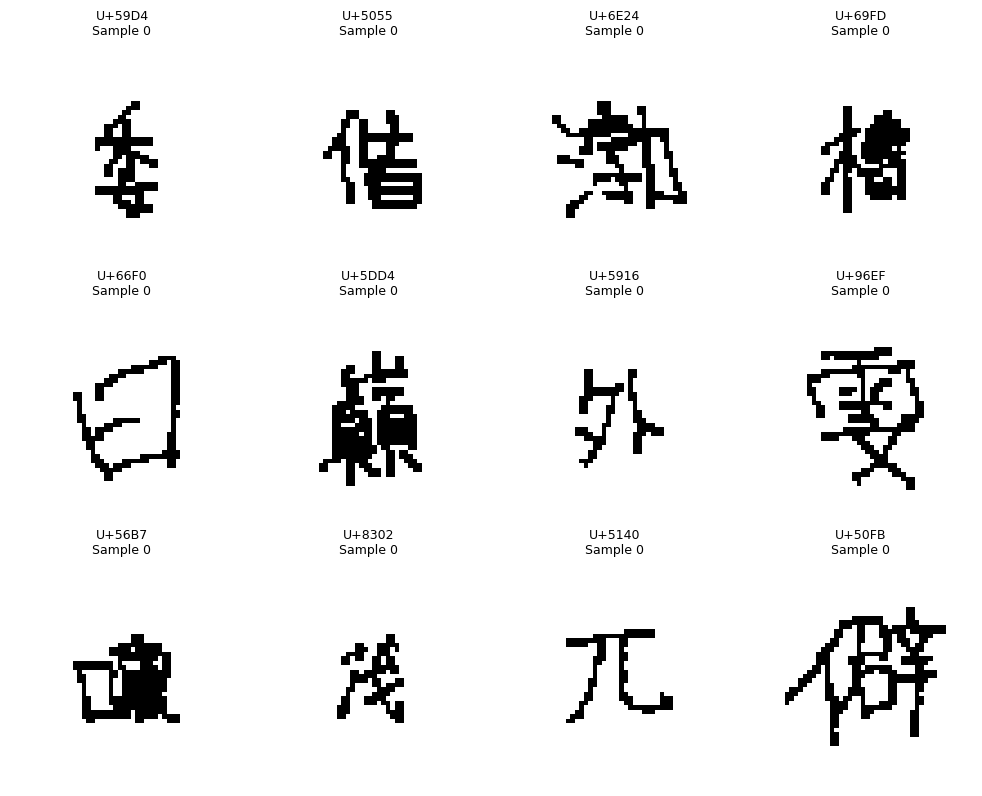

In [ ]:
import random
import zipfile
import matplotlib.pyplot as plt
from PIL import Image

if "samples_by_character" not in globals():
    raise RuntimeError("Please run the dataset statistics cell first.")

rng = random.Random(42)
characters = sorted(samples_by_character)
selected = rng.sample(characters, min(12, len(characters)))

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax in axes.flat:
    ax.axis("off")

for ax, character in zip(axes.flat, selected):
    sample_number = min(samples_by_character[character])
    record = samples_by_character[character][sample_number]

    with zipfile.ZipFile(record["archive"]) as archive:
        with archive.open(record["member"]) as file:
            with Image.open(file) as image:
                grayscale = image.convert("L")

    label = " ".join(f"U+{ord(c):04X}" for c in character)

    ax.imshow(grayscale, cmap="gray", vmin=0, vmax=255)
    ax.set_title(
        f"{label}\nSample {sample_number}",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
from IPython.display import display, Markdown

root = Path("/content/Traditional-Chinese-Handwriting-Dataset")
readme_path = root / "README.md"

if not readme_path.exists():
    raise FileNotFoundError("README.md was not found.")

readme_text = readme_path.read_text(encoding="utf-8")

display(Markdown(readme_text))

# Traditional Chinese Handwriting Dataset <a href="https://colab.research.google.com/github/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset/blob/master/Data_Deployment_colab.ipynb"><img src="https://img.shields.io/badge/%E5%AF%A6%E4%BD%9C-Colab-yellow.svg?style=popout-square" alt="範例 Colab"></a>
# 繁體中文手寫資料集

![人工智慧 - 自由團隊](https://raw.githubusercontent.com/chenkenanalytic/img/master/af/aifreeteam.png)

## Preface 前言

In the way of data science, we believe every scholar, scientists might have heard about MNIST dataset, or played with Fashion MNIST. As a traditional Chinese user, we couldn't help but wonder: is it possible for machine learning, neural networks to recognize handwritten traditional Chinese characters? Let's challenge!

在走過資料科學的路上，相信每一位學者、科學家都聽過 MNIST dataset (手寫數字資料集)，或許也玩過 Fashion MNIST；身為繁體中文使用者，難免開始好奇：手寫繁體中文是否也有機會讓機器學習、神經網路成功辨識呢？讓我們一起來挑戰！

<br>

## Description 資料集說明

Original dataset was produced based on Tegaki, an open-source package. Total 13,065 different Chinese characters, with average of 50 samples for each character.

原始資料集基於 Tegaki 開源套件下產出，總計 13,065 個不同的中文字，每一個字體平均有 50 個樣本。

<br>

## Updates 更新紀錄

 - 2021.04.17 專案衍生應用： <a href="https://traditional-chinese-handwriting.github.io/">Web-based 模型訓練、手寫辨識</a>
 - 2021.04.14 (非直接相關) 趨勢科技 T-brain 玉山人工智慧挑戰賽2021夏季賽：<a href='https://tbrain.trendmicro.com.tw/Competitions/Details/13'>繁體中文場景文字辨識競賽</a>
 - 2020.09.03 Released the whole dataset (13,065 charaters; image size: 300x300pixels; total 684,677 images)
 - 2020.04.29 分享使用繁體中文手寫字集實現卷積神經網路手寫識別實作 (感謝<a href='https://github.com/YenLinWu'> Yen-Lin 博士 </a>熱情貢獻)
 - 2020.04.21 提供資料集部署操作範例 (感謝<a href='https://github.com/YenLinWu'> Yen-Lin 博士 </a>熱情貢獻)
 - 2020.04.20 上傳最新資料集 (4,803個常用字；圖片大小：50x50pixels；共計 250,712 個圖片檔)
 (<a href='https://language.moe.gov.tw/001/Upload/Files/site_content/download/mandr/%e6%95%99%e8%82%b2%e9%83%a84808%e5%80%8b%e5%b8%b8%e7%94%a8%e5%ad%97%e8%aa%aa%e6%98%8e.pdf'>教育部 4,808 個常用字</a>)
 - 2020.04.20 Uploaded the first dataset (4,803 charaters; image size: 50x50pixels; total 250,712 images)
<br>

## Data samples 資料樣本

 - 完整資料集 - 各樣本資料夾
![完整資料集 - 各樣本資料夾](https://github.com/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset/blob/master/img/img_folder.png?raw=true)

 - 手寫"自由"範例
![手寫"自由"範例](https://github.com/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset/blob/master/img/img_samples.png?raw=true)

<br>

## Usage 使用方法

### 1. 完整資料集 - whole Dataset (13,065 characters)
``` bash
git clone https://github.com/chenkenanalytic/handwritting_data_all.git

cat (file_path)/all_data.zip* > (file_path)/all_data.zip

unzip -O big5 (file_path)/all_data.zip -d (output_path)
```
※ (file_path) & (output_path) 以實際檔案位置需求作修改、替換，解壓縮後資料夾名稱為 cleaned_data，共684,677個圖片。


<br>

#### 完整資料集 - 部署操作

<a href="https://colab.research.google.com/github/chenkenanalytic/handwritting_data_all/blob/master/Data_Deployment_all.ipynb">Colab操作程式碼參考</a>

<br>
 
### 2. 常用字資料集 - common words Dataset (4,803 characters)
``` bash
git clone https://github.com/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset.git

```
※ 下載常用字資料集後，解壓縮 data 資料夾內的四個檔案，解壓縮後資料夾名稱為 cleaned_data(50_50)，共250,712個圖片。



#### 常用字資料集 - 部署操作 (感謝<a href='https://github.com/YenLinWu'> Yen-Lin 博士 </a>熱情貢獻)

<a href="https://colab.research.google.com/github/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset/blob/master/Data_Deployment_colab.ipynb#scrollTo=BtJidZSSed2C">Colab操作程式碼參考</a>

<a href="https://github.com/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset/blob/master/Data_Deployment_local.ipynb">本地操作程式碼參考</a>

<br>
 
## Issues 問題與發現

1. 常用字資料集因壓縮至 50x50 Pixels，發現部分圖片檔筆畫不清楚、出現重疊現象。 (完整資料集較無此問題，資料為 300x300 Pixels)
2. ~~完整資料集佈署範例於 Colab 上解壓縮後，中文字集檔名會出現亂碼~~。(issue solved, please see <a href="https://github.com/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset/issues/1"> #issue 1</a>, credit to <a href="https://github.com/ling199104">ling199104</a>)


<br>

## Handwriting Chinese Characters Recognition 手寫中文辨識

<a href="https://colab.research.google.com/github/AI-FREE-Team/Handwriting-Chinese-Characters-Recognition/blob/master/Traditional_Chinese_CNN_Model_colab.ipynb"><img src="https://img.shields.io/badge/%E5%AF%A6%E4%BD%9C-Colab-yellow.svg?style=popout-square" alt="範例 Colab"></a>

<a href="https://github.com/AI-FREE-Team/Handwriting-Chinese-Characters-Recognition"> Repo Introdcution 專案介紹 </a>

使用<a href="https://github.com/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset">繁體中文手寫字集</a>實現卷積神經網路手寫識別。

Applied <a href="https://github.com/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset">Traditional-Chinese-Handwriting-Dataset</a> to realize handwriting recognition by CNN model.


若您對於進一步此實作感興趣，歡迎參考此<a href="https://aifreeblog.herokuapp.com/posts/68/Handwriting_Chinese_Characters_Recognition/">文章</a>說明。


<br>

## Project Application 專案衍伸應用 - <a href="https://traditional-chinese-handwriting.github.io/">Web-based 模型訓練、手寫辨識</a>

The application was developed based on the <a href="https://www.coursera.org/learn/browser-based-models-tensorflow/home/week/2">week 2</a> homework of <a href="https://www.coursera.org/learn/browser-based-models-tensorflow/home/welcome">Browser-based Models with TensorFlow.js</a> in <a href="https://www.coursera.org/specializations/tensorflow-data-and-deployment">TensorFlow: Data and Deployment Specialization</a> on coursera.

此衍生應用基於 Deeplearning.ai 之 Coursera 線上課程，<a href="https://www.coursera.org/specializations/tensorflow-data-and-deployment">TensorFlow: Data and Deployment Specialization</a> 的第一堂課程：<a href="https://www.coursera.org/learn/browser-based-models-tensorflow/home/welcome">Browser-based Models with TensorFlow.js</a> 的 <a href="https://www.coursera.org/learn/browser-based-models-tensorflow/home/week/2">第二週</a>線上作業所開發。 

![繁體中文手寫辨識_智](https://raw.githubusercontent.com/chenkenanalytic/img/master/tchc-ke/%E7%B9%81%E9%AB%94%E4%B8%AD%E6%96%87%E6%89%8B%E5%AF%AB%E8%BE%A8%E8%AD%98_%E6%99%BA.gif)

若您對於此專案有興趣，歡迎參考此<a href="https://aifreeblog.herokuapp.com/posts/134/Web-based_Traditional_Chinese_Handwriting_Classifier/">文章</a>說明。


<br>

## License 授權

<a rel="license" href="https://creativecommons.org/licenses/by-nc-sa/4.0/"><img alt="Creative Commons License" style="border-width:0" src="https://i.creativecommons.org/l/by-nc-sa/3.0/tw/88x31.png" /></a> (CC BY-NC-SA 4.0)<br />本資料集適用 <a rel="license" href="https://creativecommons.org/licenses/by-nc-sa/4.0/">Attribution-NonCommercial-ShareAlike 4.0 International</a> 授權。
<br />The dataset applied <a rel="license" href="https://creativecommons.org/licenses/by-nc-sa/4.0/">Attribution-NonCommercial-ShareAlike 4.0 International</a> license.

※ 使用、改作、分享請附上以下資訊：

 - 本數據集由 AI . FREE Team 改作開發自 [STUST EECS_Chinese MNIST(總集)]。如有使用、改作、分享，請註明出處及此訊息。
 
 - The dataset is AI . FREE Team development from [STUST EECS_Chinese MNIST(總集)]. If used, modified, or shared, please cite the source and the mesage.
 
 - (source: https://github.com/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset )


<br>

## Citing
```
@misc{AI.FREE2020,
  author = {Po-Chuan Chen},
  title = {Traditional Chinese Handwriting Dataset},
  year = {2020},
  publisher = {GitHub},
  journal = {GitHub repository},
  howpublished = {\url{https://github.com/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset}},
}
```
 
<br> 
 
## Source 資料來源

原資料集來源：https://scidm.nchc.org.tw/dataset/stusteecs_chinese_mnist

介紹說明影片：https://www.youtube.com/watch?v=eJy1BtkqHX4

來源說明：本數據集開發修改自南臺科技大學電子系所提供之中文手寫字集。

Description: The Dataset is developed from Chinese handwriting data set, which is provided by Dept. EECS, Southern Taiwan University of Science and Technology.


In [ ]:
import requests

api_url = "https://scidm.nchc.org.tw/api/3/action/package_show"
dataset_id = "stusteecs_chinese_mnist"

try:
    response = requests.get(
        api_url,
        params={"id": dataset_id},
        timeout=30
    )

    print("HTTP status:", response.status_code)
    print("Response URL:", response.url)

    response.raise_for_status()

    try:
        payload = response.json()
    except ValueError:
        payload = None
        print("The server did not return JSON.")
        print("Please open the dataset page in your browser.")

    if payload is not None:
        if not payload.get("success"):
            print("API request was not successful.")
            print("Details:", payload.get("error"))
        else:
            dataset = payload["result"]

            print("\n=== Dataset information ===")
            print("Title:", dataset.get("title"))
            print("License:", dataset.get("license_title"))
            print("Description:")
            print(dataset.get("notes", ""))

            resources = dataset.get("resources", [])
            print("\nNumber of resources:", len(resources))

            for index, resource in enumerate(resources, start=1):
                print("\n" + "=" * 60)
                print("Resource:", index)
                print("Name:", resource.get("name"))
                print("Format:", resource.get("format"))
                print("Size:", resource.get("size"))
                print("URL:", resource.get("url"))
                print("Description:", resource.get("description", ""))

except requests.RequestException as error:
    print("Could not access the dataset API.")
    print("Error:", error)
    print(
        "Please open this page in your browser: "
        "https://scidm.nchc.org.tw/dataset/stusteecs_chinese_mnist"
    )

Could not access the dataset API.
Error: HTTPSConnectionPool(host='scidm.nchc.org.tw', port=443): Read timed out. (read timeout=30)
Please open this page in your browser: https://scidm.nchc.org.tw/dataset/stusteecs_chinese_mnist


In [ ]:
from pathlib import Path
from collections import Counter
import subprocess

full_root = Path("/content/handwritting_data_all")
repository_url = (
    "https://github.com/chenkenanalytic/handwritting_data_all.git"
)

if not full_root.exists():
    print("Downloading the full dataset repository...", flush=True)

    subprocess.run(
        [
            "git",
            "clone",
            "--depth", "1",
            repository_url,
            str(full_root)
        ],
        check=True
    )
elif not (full_root / ".git").exists():
    raise RuntimeError(
        "The target directory exists but is not a Git repository."
    )
else:
    print("Repository already exists. Skipping download.")

result = subprocess.run(
    ["git", "-C", str(full_root), "ls-files", "-z"],
    check=True,
    capture_output=True
)

tracked_files = [
    name.decode("utf-8")
    for name in result.stdout.split(b"\0")
    if name
]

print("\n=== Repository summary ===")
print("Tracked files:", len(tracked_files))

extension_counts = Counter(
    Path(name).suffix.lower() or "(no extension)"
    for name in tracked_files
)

print("\n=== File types ===")
for extension, count in extension_counts.most_common():
    print(f"{extension}: {count}")

print("\n=== First 40 file paths ===")
for name in tracked_files[:40]:
    print(name)

print("\n=== Top-level entries ===")
for path in sorted(full_root.iterdir()):
    if path.name == ".git":
        continue

    if path.is_dir():
        print(f"[DIR]  {path.name}")
    else:
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"[FILE] {path.name} ({size_mb:.2f} MB)")


=== Repository summary ===
Tracked files: 15

=== File types ===
(no extension): 1
.ipynb: 1
.md: 1
.001: 1
.002: 1
.003: 1
.004: 1
.005: 1
.006: 1
.007: 1
.008: 1
.009: 1
.010: 1
.011: 1
.012: 1

=== First 40 file paths ===
.gitattributes
Data_Deployment_all.ipynb
README.md
all_data.zip.001
all_data.zip.002
all_data.zip.003
all_data.zip.004
all_data.zip.005
all_data.zip.006
all_data.zip.007
all_data.zip.008
all_data.zip.009
all_data.zip.010
all_data.zip.011
all_data.zip.012

=== Top-level entries ===
[FILE] .gitattributes (0.00 MB)
[FILE] Data_Deployment_all.ipynb (0.00 MB)
[FILE] README.md (0.01 MB)
[FILE] all_data.zip.001 (95.00 MB)
[FILE] all_data.zip.002 (95.00 MB)
[FILE] all_data.zip.003 (95.00 MB)
[FILE] all_data.zip.004 (95.00 MB)
[FILE] all_data.zip.005 (95.00 MB)
[FILE] all_data.zip.006 (95.00 MB)
[FILE] all_data.zip.007 (95.00 MB)
[FILE] all_data.zip.008 (95.00 MB)
[FILE] all_data.zip.009 (95.00 MB)
[FILE] all_data.zip.010 (95.00 MB)
[FILE] all_data.zip.011 (95.00 MB)
[FILE

In [ ]:
from pathlib import Path, PurePosixPath
from collections import Counter
import shutil
import zipfile

full_root = Path("/content/handwritting_data_all")
parts = [
    full_root / f"all_data.zip.{index:03d}"
    for index in range(1, 13)
]

missing = [part.name for part in parts if not part.is_file()]
if missing:
    raise FileNotFoundError(f"Missing archive parts: {missing}")

for part in parts:
    with part.open("rb") as file:
        header = file.read(128)

    if header.startswith(b"version https://git-lfs.github.com/spec/v1"):
        raise RuntimeError(
            f"{part.name} is a Git LFS pointer, not the actual data."
        )

merged_path = full_root / "all_data.zip"
temporary_path = full_root / "all_data.zip.partial"
total_size = sum(part.stat().st_size for part in parts)

if merged_path.exists() and merged_path.stat().st_size == total_size:
    print("Merged archive already exists. Skipping merge.", flush=True)
else:
    free_space = shutil.disk_usage(full_root).free

    if free_space < total_size + 512 * 1024**2:
        raise RuntimeError("Not enough free disk space to merge the archive.")

    with temporary_path.open("wb") as output:
        for index, part in enumerate(parts, start=1):
            print(
                f"Merging part {index}/{len(parts)}: {part.name}",
                flush=True
            )
            with part.open("rb") as source:
                shutil.copyfileobj(source, output, length=8 * 1024**2)

    temporary_path.replace(merged_path)

print(f"\nMerged archive size: {total_size / 1024**3:.2f} GiB")

if not zipfile.is_zipfile(merged_path):
    raise RuntimeError(
        "The merged file is not recognized as a ZIP archive. "
        "Check the repository deployment notebook before continuing."
    )

with zipfile.ZipFile(merged_path) as archive:
    entries = [
        entry for entry in archive.infolist()
        if not entry.is_dir()
    ]

    extension_counts = Counter(
        PurePosixPath(entry.filename).suffix.lower() or "(no extension)"
        for entry in entries
    )
    uncompressed_size = sum(entry.file_size for entry in entries)

    print("\n=== Archive summary ===")
    print("Total file entries:", len(entries))
    print(f"Uncompressed size: {uncompressed_size / 1024**3:.2f} GiB")

    print("\n=== File types ===")
    for extension, count in extension_counts.most_common():
        print(f"{extension}: {count}")

    print("\n=== First 30 file paths ===")
    for entry in entries[:30]:
        print(entry.filename)

print("\nArchive listing complete. No files have been extracted.")

Merging part 1/12: all_data.zip.001
Merging part 2/12: all_data.zip.002
Merging part 3/12: all_data.zip.003
Merging part 4/12: all_data.zip.004
Merging part 5/12: all_data.zip.005
Merging part 6/12: all_data.zip.006
Merging part 7/12: all_data.zip.007
Merging part 8/12: all_data.zip.008
Merging part 9/12: all_data.zip.009
Merging part 10/12: all_data.zip.010
Merging part 11/12: all_data.zip.011
Merging part 12/12: all_data.zip.012

Merged archive size: 1.06 GiB

=== Archive summary ===
Total file entries: 684677
Uncompressed size: 1.18 GiB

=== File types ===
.png: 684677

=== First 30 file paths ===
cleaned_data/10000/Σ═_0.png
cleaned_data/10000/Σ═_1.png
cleaned_data/10000/Σ═_10.png
cleaned_data/10000/Σ═_11.png
cleaned_data/10000/Σ═_12.png
cleaned_data/10000/Σ═_13.png
cleaned_data/10000/Σ═_14.png
cleaned_data/10000/Σ═_15.png
cleaned_data/10000/Σ═_16.png
cleaned_data/10000/Σ═_17.png
cleaned_data/10000/Σ═_18.png
cleaned_data/10000/Σ═_19.png
cleaned_data/10000/Σ═_2.png
cleaned_data/10000

In [ ]:
from pathlib import Path, PurePosixPath
from collections import defaultdict, Counter
from PIL import Image
import re
import zipfile

archive_path = Path("/content/handwritting_data_all/all_data.zip")
records_by_class = defaultdict(list)
invalid_names = []

with zipfile.ZipFile(archive_path) as archive:
    for entry in archive.infolist():
        if entry.is_dir():
            continue

        path = PurePosixPath(entry.filename)

        if path.suffix.lower() != ".png":
            continue

        if "__MACOSX" in path.parts or path.name.startswith("._"):
            continue

        match = re.search(r"_(\d+)$", path.stem)

        if match is None:
            invalid_names.append(entry.filename)
            continue

        class_id = str(path.parent)
        sample_number = int(match.group(1))
        records_by_class[class_id].append(
            (sample_number, entry.filename)
        )

    if not records_by_class:
        raise RuntimeError("No matching image records found.")

    first_class = sorted(records_by_class)[0]
    first_member = records_by_class[first_class][0][1]

    with archive.open(first_member) as file:
        with Image.open(file) as image:
            print("Example image size:", image.size)
            print("Example image mode:", image.mode)

counts = {
    class_id: len(records)
    for class_id, records in records_by_class.items()
}

duplicate_numbers = sum(
    len(records) - len({number for number, _ in records})
    for records in records_by_class.values()
)

print("\n=== Dataset summary ===")
print("Class folders:", len(counts))
print("Parsed images:", sum(counts.values()))
print("Minimum samples per class:", min(counts.values()))
print("Maximum samples per class:", max(counts.values()))
print("Classes with fewer than 40 samples:",
      sum(count < 40 for count in counts.values()))
print("Classes with exactly 40 samples:",
      sum(count == 40 for count in counts.values()))
print("Duplicate sample numbers within classes:", duplicate_numbers)
print("Unrecognized filenames:", len(invalid_names))

print("\n=== Sample count distribution ===")
for sample_count, class_count in sorted(Counter(counts.values()).items()):
    print(f"{sample_count} samples -> {class_count} classes")

print("\n=== First 5 class folders ===")
for class_id in sorted(records_by_class)[:5]:
    records = sorted(records_by_class[class_id])
    print("Class:", class_id)
    print("Sample numbers:", [number for number, _ in records])
    print("Example path:", records[0][1])

if invalid_names:
    print("\nUnrecognized examples:", invalid_names[:5])

print("\n=== Class-count check ===")
print("Expected classes:", 13065)
print("Observed class folders:", len(counts))
print("Class count matches:", len(counts) == 13065)

Example image size: (300, 300)
Example image mode: RGB

=== Dataset summary ===
Class folders: 13065
Parsed images: 684677
Minimum samples per class: 16
Maximum samples per class: 61
Classes with fewer than 40 samples: 43
Classes with exactly 40 samples: 0
Duplicate sample numbers within classes: 0
Unrecognized filenames: 0

=== Sample count distribution ===
16 samples -> 1 classes
17 samples -> 1 classes
18 samples -> 2 classes
20 samples -> 4 classes
21 samples -> 1 classes
22 samples -> 2 classes
23 samples -> 3 classes
27 samples -> 1 classes
31 samples -> 2 classes
32 samples -> 9 classes
33 samples -> 2 classes
34 samples -> 8 classes
35 samples -> 4 classes
36 samples -> 2 classes
37 samples -> 1 classes
47 samples -> 1 classes
48 samples -> 5 classes
49 samples -> 1915 classes
50 samples -> 2742 classes
51 samples -> 4426 classes
52 samples -> 600 classes
53 samples -> 106 classes
56 samples -> 2 classes
57 samples -> 122 classes
58 samples -> 1079 classes
59 samples -> 1429 cl

In [ ]:
from pathlib import Path, PurePosixPath
import csv
import json

if "records_by_class" not in globals():
    raise RuntimeError("Please run the full dataset statistics cell first.")

output_dir = Path("/content/handwriting_project")
output_dir.mkdir(parents=True, exist_ok=True)

class_paths = sorted(
    records_by_class,
    key=lambda value: int(PurePosixPath(value).name)
)

if len(class_paths) != 13065:
    raise ValueError(f"Expected 13065 classes, found {len(class_paths)}.")

train_rows = []
test_rows = []
shortage_rows = []
class_mapping = []

for label, class_path in enumerate(class_paths):
    records = sorted(records_by_class[class_path])
    sample_numbers = [number for number, _ in records]

    if len(sample_numbers) != len(set(sample_numbers)):
        raise ValueError(f"Duplicate sample numbers: {class_path}")

    class_mapping.append({
        "label": label,
        "class_folder": class_path
    })

    train_records = records[:40]
    test_records = records[40:]

    for destination, selected in (
        (train_rows, train_records),
        (test_rows, test_records)
    ):
        for sample_number, member in selected:
            destination.append({
                "label": label,
                "class_folder": class_path,
                "sample_number": sample_number,
                "archive_member": member
            })

    if len(records) < 40:
        shortage_rows.append({
            "label": label,
            "class_folder": class_path,
            "available_originals": len(records),
            "missing_originals": 40 - len(records)
        })

train_members = {row["archive_member"] for row in train_rows}
test_members = {row["archive_member"] for row in test_rows}

assert train_members.isdisjoint(test_members)
assert len(train_rows) + len(test_rows) == sum(
    len(records) for records in records_by_class.values()
)
assert len({row["label"] for row in train_rows}) == 13065

def save_csv(path, rows, columns):
    with path.open("w", encoding="utf-8", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)

sample_columns = [
    "label", "class_folder", "sample_number", "archive_member"
]

save_csv(output_dir / "train.csv", train_rows, sample_columns)
save_csv(output_dir / "test.csv", test_rows, sample_columns)
save_csv(
    output_dir / "shortage_classes.csv",
    shortage_rows,
    ["label", "class_folder", "available_originals", "missing_originals"]
)

with (output_dir / "class_mapping.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(class_mapping, file, indent=2, ensure_ascii=True)

print("=== Split summary ===")
print("Training originals:", len(train_rows))
print("Test originals:", len(test_rows))
print("Classes in training:", len({row["label"] for row in train_rows}))
print("Classes in testing:", len({row["label"] for row in test_rows}))
print("Classes with fewer than 40 originals:", len(shortage_rows))
print("Train/test archive-member overlap:", len(train_members & test_members))
print("Output directory:", output_dir)
print("No images have been extracted or augmented.")

=== Split summary ===
Training originals: 522127
Test originals: 162550
Classes in training: 13065
Classes in testing: 13022
Classes with fewer than 40 originals: 43
Train/test archive-member overlap: 0
Output directory: /content/handwriting_project
No images have been extracted or augmented.


In [ ]:
from pathlib import Path
import csv
import json
import shutil
import zipfile
import tensorflow as tf

project_dir = Path("/content/handwriting_project")
archive_path = Path("/content/handwritting_data_all/all_data.zip")
output_dir = project_dir / "tfrecords"
metadata_path = output_dir / "metadata.json"

shard_size = 10000

def bytes_feature(value):
    return tf.train.Feature(
        bytes_list=tf.train.BytesList(value=[value])
    )

def int_feature(value):
    return tf.train.Feature(
        int64_list=tf.train.Int64List(value=[value])
    )

def convert_split(archive, split):
    manifest_path = project_dir / f"{split}.csv"
    writer = None
    temporary_path = None
    final_path = None
    total = 0
    shard_paths = []

    try:
        with manifest_path.open(
            "r", encoding="utf-8", newline=""
        ) as file:
            for row in csv.DictReader(file):
                if total % shard_size == 0:
                    if writer is not None:
                        writer.close()
                        writer = None
                        temporary_path.replace(final_path)

                    shard_index = total // shard_size
                    final_path = (
                        output_dir / f"{split}-{shard_index:05d}.tfrecord"
                    )
                    temporary_path = Path(str(final_path) + ".partial")
                    writer = tf.io.TFRecordWriter(str(temporary_path))
                    shard_paths.append(final_path.name)

                member = row["archive_member"]
                image_bytes = archive.read(member)

                example = tf.train.Example(
                    features=tf.train.Features(feature={
                        "image": bytes_feature(image_bytes),
                        "label": int_feature(int(row["label"])),
                        "source": bytes_feature(member.encode("utf-8"))
                    })
                )

                writer.write(example.SerializeToString())
                total += 1

                if total % shard_size == 0:
                    print(f"{split}: {total:,} images written", flush=True)

        if writer is not None:
            writer.close()
            writer = None
            temporary_path.replace(final_path)

    finally:
        if writer is not None:
            writer.close()

    print(f"{split}: complete, {total:,} images", flush=True)

    return {
        "count": total,
        "shards": shard_paths
    }

if metadata_path.exists():
    print("Conversion already completed.")
    print(metadata_path.read_text(encoding="utf-8"))
else:
    required_files = [
        archive_path,
        project_dir / "train.csv",
        project_dir / "test.csv",
        project_dir / "class_mapping.json"
    ]

    for path in required_files:
        if not path.is_file():
            raise FileNotFoundError(str(path))

    if shutil.disk_usage(project_dir).free < 3 * 1024**3:
        raise RuntimeError("At least 3 GiB of free disk space is required.")

    output_dir.mkdir(parents=True, exist_ok=True)

    with (project_dir / "class_mapping.json").open(
        "r", encoding="utf-8"
    ) as file:
        class_mapping = json.load(file)

    metadata = {
        "num_classes": len(class_mapping),
        "image_storage": "original PNG bytes",
        "augmentation_applied": False
    }

    with zipfile.ZipFile(archive_path) as archive:
        metadata["train"] = convert_split(archive, "train")
        metadata["test"] = convert_split(archive, "test")

    if metadata["train"]["count"] != 522127:
        raise RuntimeError("Unexpected training image count.")

    if metadata["test"]["count"] != 162550:
        raise RuntimeError("Unexpected test image count.")

    metadata_path.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    print("\n=== Conversion complete ===")
    print("Training images:", metadata["train"]["count"])
    print("Test images:", metadata["test"]["count"])
    print("Training shards:", len(metadata["train"]["shards"]))
    print("Test shards:", len(metadata["test"]["shards"]))
    print("Output directory:", output_dir)

train: 10,000 images written
train: 20,000 images written
train: 30,000 images written
train: 40,000 images written
train: 50,000 images written
train: 60,000 images written
train: 70,000 images written
train: 80,000 images written
train: 90,000 images written
train: 100,000 images written
train: 110,000 images written
train: 120,000 images written
train: 130,000 images written
train: 140,000 images written
train: 150,000 images written
train: 160,000 images written
train: 170,000 images written
train: 180,000 images written
train: 190,000 images written
train: 200,000 images written
train: 210,000 images written
train: 220,000 images written
train: 230,000 images written
train: 240,000 images written
train: 250,000 images written
train: 260,000 images written
train: 270,000 images written
train: 280,000 images written
train: 290,000 images written
train: 300,000 images written
train: 310,000 images written
train: 320,000 images written
train: 330,000 images written
train: 340,000 imag

In [ ]:
from pathlib import Path
from collections import defaultdict
import csv
import json
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

project_dir = Path("/content/handwriting_project")
record_dir = project_dir / "tfrecords"

with (record_dir / "metadata.json").open(
    "r", encoding="utf-8"
) as file:
    metadata = json.load(file)

NUM_CLASSES = metadata["num_classes"]
IMAGE_SIZE = (50, 50)
BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE

rows_by_label = defaultdict(list)

with (project_dir / "train.csv").open(
    "r", encoding="utf-8", newline=""
) as file:
    for row in csv.DictReader(file):
        rows_by_label[int(row["label"])].append(row)

fit_rows = []
validation_rows = []

for label in sorted(rows_by_label):
    rows = sorted(
        rows_by_label[label],
        key=lambda row: int(row["sample_number"])
    )

    if len(rows) <= 4:
        raise ValueError(f"Not enough training samples for label {label}.")

    fit_rows.extend(rows[:-4])
    validation_rows.extend(rows[-4:])

columns = [
    "label", "class_folder", "sample_number", "archive_member"
]

for filename, rows in (
    ("fit.csv", fit_rows),
    ("validation.csv", validation_rows)
):
    with (project_dir / filename).open(
        "w", encoding="utf-8", newline=""
    ) as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)

validation_sources = [
    row["archive_member"] for row in validation_rows
]

validation_lookup = tf.lookup.StaticHashTable(
    tf.lookup.KeyValueTensorInitializer(
        keys=tf.constant(validation_sources, dtype=tf.string),
        values=tf.ones(len(validation_sources), dtype=tf.int32)
    ),
    default_value=0
)

feature_spec = {
    "image": tf.io.FixedLenFeature([], tf.string),
    "label": tf.io.FixedLenFeature([], tf.int64),
    "source": tf.io.FixedLenFeature([], tf.string)
}

def parse_record(serialized):
    return tf.io.parse_single_example(serialized, feature_spec)

def is_validation(record):
    return tf.equal(validation_lookup.lookup(record["source"]), 1)

def is_fit(record):
    return tf.equal(validation_lookup.lookup(record["source"]), 0)

def decode_record(record):
    image = tf.io.decode_png(record["image"], channels=1)
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.ensure_shape(image, (50, 50, 1))

    label = tf.cast(record["label"], tf.int32)
    return image, label

train_files = [
    str(record_dir / name)
    for name in metadata["train"]["shards"]
]

raw_train = tf.data.TFRecordDataset(
    train_files,
    num_parallel_reads=AUTOTUNE
).map(parse_record, num_parallel_calls=AUTOTUNE)

fit_ds = (
    raw_train
    .filter(is_fit)
    .shuffle(10000, seed=42, reshuffle_each_iteration=True)
    .map(decode_record, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

validation_ds = (
    raw_train
    .filter(is_validation)
    .map(decode_record, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("=== Dataset configuration ===", flush=True)
print("Classes:", NUM_CLASSES)
print("Fit originals:", len(fit_rows))
print("Validation originals:", len(validation_rows))
print("Reserved test originals:", metadata["test"]["count"])
print("GPU devices:", tf.config.list_physical_devices("GPU"))

print("\nReading one training batch...", flush=True)

images, labels = next(iter(fit_ds))

tf.debugging.assert_all_finite(images, "Images contain invalid values.")
tf.debugging.assert_greater_equal(labels, 0)
tf.debugging.assert_less(labels, NUM_CLASSES)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype.name)
print("Pixel minimum:", float(tf.reduce_min(images)))
print("Pixel maximum:", float(tf.reduce_max(images)))
print("Augmentation applied: False")
print("Dataset pipeline is ready.")

=== Dataset configuration ===
Classes: 13065
Fit originals: 469867
Validation originals: 52260
Reserved test originals: 162550
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Reading one training batch...
Image batch shape: (128, 50, 50, 1)
Label batch shape: (128,)
Image dtype: float32
Pixel minimum: 0.0
Pixel maximum: 1.0
Augmentation applied: False
Dataset pipeline is ready.


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

if "fit_ds" not in globals():
    raise RuntimeError("Please run the dataset pipeline cell first.")

tf.keras.utils.set_random_seed(42)

# Use mixed precision for the T4 GPU.
keras.mixed_precision.set_global_policy("mixed_float16")

augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.025,
            fill_mode="constant",
            fill_value=1.0,
            seed=42
        ),
        layers.RandomTranslation(
            height_factor=0.08,
            width_factor=0.08,
            fill_mode="constant",
            fill_value=1.0,
            seed=43
        ),
        layers.RandomZoom(
            height_factor=(-0.08, 0.08),
            width_factor=(-0.08, 0.08),
            fill_mode="constant",
            fill_value=1.0,
            seed=44
        )
    ],
    name="augmentation"
)

def build_baseline(num_classes):
    inputs = keras.Input(shape=(50, 50, 1), name="image")
    x = augmentation(inputs)

    # Convert white background to zero.
    x = layers.Rescaling(scale=-1.0, offset=1.0)(x)

    for filters in (32, 64, 128):
        x = layers.Conv2D(
            filters,
            kernel_size=3,
            padding="same",
            use_bias=False
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(pool_size=2)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax",
        dtype="float32",
        name="predictions"
    )(x)

    model = keras.Model(inputs, outputs, name="baseline_cnn")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
            keras.metrics.SparseTopKCategoricalAccuracy(
                k=5,
                name="top5_accuracy"
            )
        ]
    )
    return model

model = build_baseline(NUM_CLASSES)
model.summary()

images, labels = next(iter(fit_ds))

# Check augmentation without updating model weights.
augmented_images = augmentation(images, training=True)
tf.debugging.assert_all_finite(
    augmented_images,
    "Augmented images contain invalid values."
)

# Check inference and loss without training.
results = model.test_on_batch(
    images,
    labels,
    return_dict=True
)
model.reset_metrics()

print("\n=== Model check ===")
print("Output shape:", model.output_shape)
print("Parameter count:", model.count_params())
print("Precision policy:", keras.mixed_precision.global_policy().name)
print("Augmented batch shape:", augmented_images.shape)

for name, value in results.items():
    print(f"{name}: {float(value):.6f}")

print("Model check complete. No training has been performed.")

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 50, 50, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 50, 50, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 50, 50, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 50, 50, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 50, 50, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 25, 25, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 25, 25, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 13065)          │     3,357,705 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,630,953 (17.67 MB)

 Trainable params: 4,630,505 (17.66 MB)

 Non-trainable params: 448 (1.75 KB)


=== Model check ===
Output shape: (None, 13065)
Parameter count: 4630953
Precision policy: mixed_float16
Augmented batch shape: (128, 50, 50, 1)
accuracy: 0.000000
loss: 9.477810
top5_accuracy: 0.000000
Model check complete. No training has been performed.


In [ ]:
from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
import shutil

drive.mount("/content/drive")

project_dir = Path("/content/handwriting_project")
run_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")

run_dir = (
    Path("/content/drive/MyDrive")
    / "handwriting_project"
    / f"baseline_{run_id}"
)
run_dir.mkdir(parents=True, exist_ok=True)

for filename in [
    "train.csv",
    "test.csv",
    "fit.csv",
    "validation.csv",
    "shortage_classes.csv",
    "class_mapping.json"
]:
    source = project_dir / filename
    if not source.is_file():
        raise FileNotFoundError(str(source))
    shutil.copy2(source, run_dir / filename)

model.save(run_dir / "initial_model.keras")

print("Backup complete.")
print("Run directory:", run_dir)
print("Image data and TFRecord shards were not copied.")

Mounted at /content/drive
Backup complete.
Run directory: /content/drive/MyDrive/handwriting_project/baseline_20261120_055158
Image data and TFRecord shards were not copied.


In [ ]:
from collections import defaultdict
import csv
import math
import shutil
import tensorflow as tf

required_names = [
    "fit_rows", "raw_train", "is_fit", "decode_record",
    "project_dir", "run_dir", "BATCH_SIZE", "AUTOTUNE"
]

missing = [name for name in required_names if name not in globals()]
if missing:
    raise RuntimeError(f"Missing variables: {missing}")

TARGET_PER_CLASS = 200
fit_by_label = defaultdict(list)

for row in fit_rows:
    fit_by_label[int(row["label"])].append(row)

repeat_sources = []
repeat_counts = []
plan_path = project_dir / "augmentation_plan.csv"

with plan_path.open("w", encoding="utf-8", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["label", "archive_member", "uses_per_epoch"])

    for label in sorted(fit_by_label):
        rows = sorted(
            fit_by_label[label],
            key=lambda row: int(row["sample_number"])
        )

        base, remainder = divmod(TARGET_PER_CLASS, len(rows))
        class_total = 0

        for index, row in enumerate(rows):
            uses = base + int(index < remainder)
            source = row["archive_member"]

            repeat_sources.append(source)
            repeat_counts.append(uses)
            class_total += uses

            writer.writerow([label, source, uses])

        assert class_total == TARGET_PER_CLASS

repeat_lookup = tf.lookup.StaticHashTable(
    tf.lookup.KeyValueTensorInitializer(
        keys=tf.constant(repeat_sources, dtype=tf.string),
        values=tf.constant(repeat_counts, dtype=tf.int64)
    ),
    default_value=tf.constant(0, dtype=tf.int64)
)

def repeat_record(record):
    count = repeat_lookup.lookup(record["source"])
    return tf.data.Dataset.from_tensors(record).repeat(count)

TRAIN_EXAMPLES = len(fit_by_label) * TARGET_PER_CLASS
STEPS_PER_EPOCH = math.ceil(TRAIN_EXAMPLES / BATCH_SIZE)

balanced_train_ds = (
    raw_train
    .filter(is_fit)
    .flat_map(repeat_record)
    .apply(tf.data.experimental.assert_cardinality(TRAIN_EXAMPLES))
    .shuffle(20000, seed=42, reshuffle_each_iteration=True)
    .map(decode_record, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

shutil.copy2(plan_path, run_dir / plan_path.name)

print("=== Training plan ===")
print("Classes:", len(fit_by_label))
print("Examples per class per epoch:", TARGET_PER_CLASS)
print("Total examples per epoch:", TRAIN_EXAMPLES)
print("Batch size:", BATCH_SIZE)
print("Batches per epoch:", STEPS_PER_EPOCH)
print("Augmentation: online, inside the model")
print("Validation images used for training: False")
print("Test images used for training: False")
print("Training has not started.")

=== Training plan ===
Classes: 13065
Examples per class per epoch: 200
Total examples per epoch: 2613000
Batch size: 128
Batches per epoch: 20415
Augmentation: online, inside the model
Validation images used for training: False
Test images used for training: False
Training has not started.


In [ ]:
import time
import gc
import json
import tensorflow as tf

required_names = [
    "balanced_train_ds", "run_dir", "STEPS_PER_EPOCH"
]

missing = [name for name in required_names if name not in globals()]
if missing:
    raise RuntimeError(f"Missing variables: {missing}")

WARMUP_STEPS = 20
MEASURE_STEPS = 200
TOTAL_STEPS = WARMUP_STEPS + MEASURE_STEPS

initial_path = run_dir / "initial_model.keras"

if not initial_path.is_file():
    raise FileNotFoundError(str(initial_path))

benchmark_model = tf.keras.models.load_model(
    initial_path,
    compile=False
)

benchmark_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ],
    jit_compile=False,
    steps_per_execution=1
)

class SpeedTimer(tf.keras.callbacks.Callback):
    def __init__(self, warmup_steps):
        super().__init__()
        self.warmup_steps = warmup_steps
        self.start_time = None
        self.elapsed = None
        self.measured_batches = 0

    def on_train_batch_begin(self, batch, logs=None):
        if batch == self.warmup_steps:
            self.start_time = time.perf_counter()

    def on_train_batch_end(self, batch, logs=None):
        if batch >= self.warmup_steps:
            self.measured_batches += 1
            self.elapsed = time.perf_counter() - self.start_time

timer = SpeedTimer(WARMUP_STEPS)

print("Starting benchmark on a separate model.", flush=True)
print("The first batches may be slower.", flush=True)

wall_start = time.perf_counter()

benchmark_model.fit(
    balanced_train_ds.take(TOTAL_STEPS),
    epochs=1,
    steps_per_epoch=TOTAL_STEPS,
    callbacks=[timer],
    verbose=1
)

wall_seconds = time.perf_counter() - wall_start

if not timer.measured_batches or timer.elapsed is None:
    raise RuntimeError("The benchmark did not complete.")

seconds_per_batch = timer.elapsed / timer.measured_batches
estimated_epoch_minutes = (
    seconds_per_batch * STEPS_PER_EPOCH / 60
)

results = {
    "warmup_batches": WARMUP_STEPS,
    "measured_batches": timer.measured_batches,
    "seconds_per_batch": seconds_per_batch,
    "estimated_training_minutes_per_epoch": estimated_epoch_minutes,
    "benchmark_wall_seconds": wall_seconds,
    "includes_validation_and_saving": False
}

(run_dir / "benchmark.json").write_text(
    json.dumps(results, indent=2),
    encoding="utf-8"
)

print("\n=== Benchmark result ===")
print(f"Seconds per batch: {seconds_per_batch:.4f}")
print(
    "Estimated training time per full epoch: "
    f"{estimated_epoch_minutes:.1f} minutes"
)
print(f"Benchmark total time: {wall_seconds / 60:.1f} minutes")
print("The estimate excludes validation and checkpoint saving.")
print("The main model was not modified.")
print("Benchmark results saved.")

del benchmark_model
gc.collect()

Starting benchmark on a separate model.
The first batches may be slower.
220/220 ━━━━━━━━━━━━━━━━━━━━ 45s 138ms/step - accuracy: 0.0358 - loss: 5.5683

=== Benchmark result ===
Seconds per batch: 0.1425
Estimated training time per full epoch: 48.5 minutes
Benchmark total time: 0.8 minutes
The estimate excludes validation and checkpoint saving.
The main model was not modified.
Benchmark results saved.


0

In [ ]:
import json
import tensorflow as tf

In [ ]:
print("Training log saved:", run_dir / "training_log.csv")

Training log saved: /content/drive/MyDrive/handwriting_project/baseline_20261120_055158/training_log.csv


In [ ]:
import json
import tensorflow as tf

# 1. Check required variables.
required_names = [
    "model",
    "balanced_train_ds",
    "validation_ds",
    "run_dir",
    "STEPS_PER_EPOCH"
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(f"Missing variables: {missing}")

if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("No GPU detected. Check the runtime settings.")

run_dir.mkdir(parents=True, exist_ok=True)

# 2. Configure the first training round.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top5_accuracy"
        )
    ],
    jit_compile=False,
    steps_per_execution=1
)

# 3. Configure automatic saving.
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(run_dir / "recovery_model.keras"),
        save_best_only=False,
        save_freq=2000,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(run_dir / "best_model.keras"),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_freq="epoch",
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(
        str(run_dir / "training_log.csv"),
        append=False
    ),
    tf.keras.callbacks.TerminateOnNaN()
]

# 4. Actually start training.
print("Starting the first full training epoch.", flush=True)
print("Training batches:", STEPS_PER_EPOCH)
print("Checkpoint directory:", run_dir)
print("The test dataset will not be used.", flush=True)

history = model.fit(
    balanced_train_ds,
    validation_data=validation_ds,
    epochs=1,
    callbacks=callbacks,
    verbose=1
)

# 5. Save the model and results after training.
model.save(run_dir / "last_model.keras")

history_data = {
    key: [float(value) for value in values]
    for key, values in history.history.items()
}

(run_dir / "first_epoch_history.json").write_text(
    json.dumps(history_data, indent=2),
    encoding="utf-8"
)

print("\n=== First epoch result ===")

for name, values in history_data.items():
    print(f"{name}: {values[-1]:.6f}")

print("Final model saved:", run_dir / "last_model.keras")
print("Training log saved:", run_dir / "training_log.csv")

Starting the first full training epoch.
Training batches: 20415
Checkpoint directory: /content/drive/MyDrive/handwriting_project/baseline_20261120_055158
The test dataset will not be used.
 1999/20415 ━━━━━━━━━━━━━━━━━━━━ 45:07 147ms/step - accuracy: 0.0427 - loss: 6.2032 - top5_accuracy: 0.1306
Epoch 1: saving model to /content/drive/MyDrive/handwriting_project/baseline_20261120_055158/recovery_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/handwriting_project/baseline_20261120_055158/recovery_model.keras
 3999/20415 ━━━━━━━━━━━━━━━━━━━━ 40:19 147ms/step - accuracy: 0.0316 - loss: 6.9390 - top5_accuracy: 0.0973
Epoch 1: saving model to /content/drive/MyDrive/handwriting_project/baseline_20261120_055158/recovery_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/handwriting_project/baseline_20261120_055158/recovery_model.keras
 5999/20415 ━━━━━━━━━━━━━━━━━━━━ 35:48 149ms/step - accuracy: 0.0258 - loss: 7.3216 - top5_accuracy: 0.0801
Epoch 1: sa

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/handwriting_project/baseline_20261120_055158/best_model.keras
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 3170s 155ms/step - accuracy: 0.0347 - loss: 8.2682 - top5_accuracy: 0.0929 - val_accuracy: 1.1481e-04 - val_loss: 12.9848 - val_top5_accuracy: 6.6973e-04

=== First epoch result ===
accuracy: 0.034728
loss: 8.268205
top5_accuracy: 0.092881
val_accuracy: 0.000115
val_loss: 12.984765
val_top5_accuracy: 0.000670
Final model saved: /content/drive/MyDrive/handwriting_project/baseline_20261120_055158/last_model.keras
Training log saved: /content/drive/MyDrive/handwriting_project/baseline_20261120_055158/training_log.csv


In [ ]:
import numpy as np
from collections import Counter

def inspect_dataset(name, dataset, batches):
    labels = []
    image_min = float("inf")
    image_max = float("-inf")
    first_shape = None
    first_dtype = None

    for images, targets in dataset.take(batches):
        x = images.numpy()
        y = targets.numpy()

        if first_shape is None:
            first_shape = x.shape
            first_dtype = str(x.dtype)

        # This model expects one integer label per image.
        if y.ndim > 1 and y.shape[-1] != 1:
            raise ValueError(
                f"{name}: unexpected label shape {y.shape}"
            )

        labels.extend(y.reshape(-1).tolist())
        image_min = min(image_min, float(np.min(x)))
        image_max = max(image_max, float(np.max(x)))

    if not labels:
        raise RuntimeError(f"{name}: dataset is empty")

    counts = Counter(labels)
    total = len(labels)
    top10 = counts.most_common(10)
    top10_share = sum(count for _, count in top10) / total

    print(f"\n=== {name} ===")
    print("First image batch shape:", first_shape)
    print("Image dtype:", first_dtype)
    print("Image value range:", (image_min, image_max))
    print("Examples inspected:", total)
    print("Unique labels:", len(counts))
    print("Sample label range:", (min(labels), max(labels)))
    print("Most frequent labels (label, count):", top10)
    print(f"Top 10 labels' share: {top10_share:.2%}")
    print("First 40 labels:", labels[:40])

inspect_dataset(
    "TRAIN: first 30 batches",
    balanced_train_ds,
    batches=30
)

inspect_dataset(
    "VALIDATION: first 5 batches",
    validation_ds,
    batches=5
)

print("\nInspection complete. No model weights were changed.")


=== TRAIN: first 30 batches ===
First image batch shape: (128, 50, 50, 1)
Image dtype: float32
Image value range: (0.0, 1.0)
Examples inspected: 3840
Unique labels: 118
Sample label range: (0, 117)
Most frequent labels (label, count): [(70, 46), (13, 46), (21, 45), (83, 44), (32, 44), (95, 44), (37, 43), (63, 43), (6, 43), (14, 42)]
Top 10 labels' share: 11.46%
First 40 labels: [83, 86, 41, 39, 34, 89, 21, 92, 37, 28, 15, 51, 32, 30, 70, 97, 74, 44, 63, 37, 14, 94, 69, 84, 30, 85, 38, 70, 30, 74, 17, 25, 13, 10, 61, 60, 86, 42, 94, 83]

=== VALIDATION: first 5 batches ===
First image batch shape: (128, 50, 50, 1)
Image dtype: float32
Image value range: (0.0, 1.0)
Examples inspected: 640
Unique labels: 160
Sample label range: (0, 159)
Most frequent labels (label, count): [(0, 4), (1, 4), (2, 4), (3, 4), (4, 4), (5, 4), (6, 4), (7, 4), (8, 4), (9, 4)]
Top 10 labels' share: 6.25%
First 40 labels: [0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3, 4, 4, 4, 4, 5, 5, 5, 5, 6, 6, 6, 6, 7, 7, 7

In [ ]:
import inspect
import tensorflow as tf

print("=== Model preprocessing layers ===")

def show_preprocessing(container, prefix=""):
    for layer in container.layers:
        path = f"{prefix}/{layer.name}" if prefix else layer.name

        if isinstance(layer, tf.keras.layers.Rescaling):
            config = layer.get_config()
            print("Rescaling layer:", path)
            print("  scale:", config["scale"])
            print("  offset:", config["offset"])

        if layer.name == "augmentation":
            print("\nAugmentation config:")
            print(layer.get_config())

        if isinstance(layer, tf.keras.Model):
            show_preprocessing(layer, path)

show_preprocessing(model)

print("\n=== decode_record source ===")

decode_fn = getattr(decode_record, "python_function", decode_record)

try:
    print(inspect.getsource(decode_fn))
except (OSError, TypeError):
    print(
        "Cannot retrieve source automatically. "
        "Please copy the cell that defines decode_record."
    )

print("\n=== Output activation ===")
last_layer = model.layers[-1]
activation = getattr(last_layer, "activation", None)

print("Last layer:", last_layer.name)
print("Activation:", getattr(activation, "__name__", str(activation)))

print("\nInspection complete. No training or saving was performed.")

=== Model preprocessing layers ===

Augmentation config:
{'name': 'augmentation', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'mixed_float16'}, 'registered_name': None}, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_shape': (None, 50, 50, 1), 'dtype': 'float16', 'sparse': False, 'ragged': False, 'name': 'input_layer', 'optional': False}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'mixed_float16'}, 'registered_name': None}, 'factor': (-0.025, 0.025), 'data_format': 'channels_last', 'fill_mode': 'constant', 'fill_value': 1.0, 'interpolation': 'bilinear', 'seed': 42}, 'registered_name': None, 'build_config': {'input_shape': (None, 50, 50, 1)}}, {'module': 'keras.layers', 'class_name': 'RandomTranslation', 'config': {'name': 'ra

In [ ]:
import tensorflow as tf
import psutil

required_names = ["raw_train", "is_fit", "fit_rows"]
missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(f"Missing variables: {missing}")

print(
    "Scanning encoded training images. No training is performed...",
    flush=True
)

def accumulate_sizes(state, record):
    count, image_bytes, source_bytes = state

    return (
        count + tf.constant(1, tf.int64),
        image_bytes + tf.cast(
            tf.strings.length(record["image"], unit="BYTE"),
            tf.int64
        ),
        source_bytes + tf.cast(
            tf.strings.length(record["source"], unit="BYTE"),
            tf.int64
        )
    )

count, image_bytes, source_bytes = (
    raw_train
    .filter(is_fit)
    .reduce(
        initial_state=(
            tf.constant(0, tf.int64),
            tf.constant(0, tf.int64),
            tf.constant(0, tf.int64)
        ),
        reduce_func=accumulate_sizes
    )
)

count = int(count.numpy())
image_bytes = int(image_bytes.numpy())
source_bytes = int(source_bytes.numpy())

gib = 1024 ** 3
memory = psutil.virtual_memory()

print("\n=== Shuffle planning ===")
print("Training original records:", count)
print("Expected records from fit_rows:", len(fit_rows))
print(f"Encoded image payload: {image_bytes / gib:.3f} GiB")
print(f"Source string payload: {source_bytes / gib:.3f} GiB")
print(f"System RAM total: {memory.total / gib:.2f} GiB")
print(f"System RAM available: {memory.available / gib:.2f} GiB")
print("Actual shuffle memory also includes TensorFlow overhead.")

if count != len(fit_rows):
    print("WARNING: Record count does not match fit_rows.")

print("Scan complete. No model weights or files were changed.")

Scanning encoded training images. No training is performed...

=== Shuffle planning ===
Training original records: 469867
Expected records from fit_rows: 469867
Encoded image payload: 0.798 GiB
Source string payload: 0.013 GiB
System RAM total: 12.67 GiB
System RAM available: 7.48 GiB
Actual shuffle memory also includes TensorFlow overhead.
Scan complete. No model weights or files were changed.


In [ ]:
import tensorflow as tf
import numpy as np
from collections import Counter
import psutil

required = [
    "raw_train", "is_fit", "fit_rows", "repeat_record",
    "TRAIN_EXAMPLES", "BATCH_SIZE", "decode_record"
]
missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(f"Missing variables: {missing}")

print("Building corrected training dataset.", flush=True)
print("Original training images:", len(fit_rows))
print("Planned inputs per epoch:", TRAIN_EXAMPLES)

# Shuffle ALL encoded training originals BEFORE repeating them.
# Keep the original repetition rules unchanged.
fixed_train_ds = (
    raw_train
    .filter(is_fit)
    .shuffle(
        buffer_size=len(fit_rows),
        seed=42,
        reshuffle_each_iteration=True
    )
    .flat_map(repeat_record)
    .apply(
        tf.data.experimental.assert_cardinality(TRAIN_EXAMPLES)
    )
    .shuffle(
        buffer_size=20000,
        seed=43,
        reshuffle_each_iteration=True
    )
    .map(decode_record, num_parallel_calls=2)
    .batch(BATCH_SIZE)
    .prefetch(1)
)

print(
    "\nChecking the first 30 batches. "
    "The full shuffle buffer must fill before results appear.",
    flush=True
)

def inspect_fixed_dataset(dataset):
    counts = Counter()
    first_labels = []
    total = 0
    image_min = float("inf")
    image_max = float("-inf")

    for batch_no, (images, labels) in enumerate(
        dataset.take(30), start=1
    ):
        x = images.numpy()
        y = labels.numpy().reshape(-1)

        counts.update(int(label) for label in y)
        total += len(y)

        if batch_no == 1:
            first_labels = y[:40].tolist()

        image_min = min(image_min, float(np.min(x)))
        image_max = max(image_max, float(np.max(x)))

    if total == 0:
        raise RuntimeError("The corrected dataset is empty.")

    top10 = counts.most_common(10)

    print("\n=== Corrected shuffle check ===")
    print("Examples inspected:", total)
    print("Unique labels:", len(counts))
    print("Sample label range:", (min(counts), max(counts)))
    print("Most frequent labels (label, count):", top10)
    print(
        "Top 10 labels' share:",
        f"{sum(n for _, n in top10) / total:.2%}"
    )
    print("First 40 labels:", first_labels)
    print("Image value range:", (image_min, image_max))

inspect_fixed_dataset(fixed_train_ds)

print(
    "\nAvailable RAM:",
    f"{psutil.virtual_memory().available / 1024**3:.2f} GiB"
)
print("Check complete. No training or saving was performed.")

Building corrected training dataset.
Original training images: 469867
Planned inputs per epoch: 2613000

Checking the first 30 batches. The full shuffle buffer must fill before results appear.

=== Corrected shuffle check ===
Examples inspected: 3840
Unique labels: 2401
Sample label range: (1, 13062)
Most frequent labels (label, count): [(6153, 7), (6667, 6), (2998, 6), (8330, 6), (3201, 6), (10115, 6), (10721, 5), (6126, 5), (12008, 5), (9667, 5)]
Top 10 labels' share: 1.48%
First 40 labels: [5903, 3034, 8726, 9228, 10737, 12492, 10156, 576, 6667, 7884, 863, 3525, 10721, 6126, 3377, 8443, 11869, 6300, 4122, 2998, 587, 6153, 12444, 2528, 1438, 2748, 1190, 6137, 12337, 7967, 10509, 2849, 6099, 4336, 8643, 3940, 6248, 8555, 384, 12411]
Image value range: (0.0, 1.0)

Available RAM: 5.32 GiB
Check complete. No training or saving was performed.


In [ ]:
import tensorflow as tf
import numpy as np

required = ["model", "fixed_train_ds"]
missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(f"Missing variables: {missing}")

if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("No GPU detected. Check runtime settings.")

# A separate model with fresh weights.
# Do NOT copy weights from the previous model.
tf.keras.utils.set_random_seed(42)
trial_model = tf.keras.models.clone_model(model)

trial_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top5_accuracy"
        )
    ],
    jit_compile=False,
    steps_per_execution=1
)

# Record cumulative metrics every 200 batches.
class ProgressCheck(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.records = []

    def on_train_batch_end(self, batch, logs=None):
        logs = logs or {}

        if (batch + 1) % 200 == 0:
            self.records.append({
                "batch": batch + 1,
                **{
                    name: float(value)
                    for name, value in logs.items()
                }
            })

progress_check = ProgressCheck()

print("Starting a 1,000-batch trial with fresh weights.", flush=True)
print("Using fixed_train_ds.", flush=True)
print("The shuffle buffer must fill before training starts.", flush=True)
print("Original model and saved files will not be changed.", flush=True)

trial_history = trial_model.fit(
    fixed_train_ds.take(1000),
    epochs=1,
    callbacks=[
        progress_check,
        tf.keras.callbacks.TerminateOnNaN()
    ],
    verbose=1
)

print("\n=== Trial progress: cumulative metrics ===")
for record in progress_check.records:
    print(
        f"Batch {record['batch']:4d} | "
        f"loss: {record.get('loss', float('nan')):.4f} | "
        f"accuracy: {record.get('accuracy', float('nan')):.6f} | "
        f"top5: {record.get('top5_accuracy', float('nan')):.6f}"
    )

print("\n=== Trial result ===")
for name, values in trial_history.history.items():
    print(f"{name}: {float(values[-1]):.6f}")

loss_values = trial_history.history.get("loss", [])
if loss_values and not np.all(np.isfinite(loss_values)):
    print("WARNING: Non-finite loss detected.")

print("\nTrial model remains in memory as trial_model.")
print("No files were saved. The original model was not changed.")

Starting a 1,000-batch trial with fresh weights.
Using fixed_train_ds.
The shuffle buffer must fill before training starts.
Original model and saved files will not be changed.
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 189s 149ms/step - accuracy: 4.2969e-04 - loss: 9.3529 - top5_accuracy: 0.0020

=== Trial progress: cumulative metrics ===
Batch  200 | loss: 9.1579 | accuracy: 0.000547 | top5: 0.003086
Batch  400 | loss: 9.2297 | accuracy: 0.000605 | top5: 0.003066
Batch  600 | loss: 9.2917 | accuracy: 0.000469 | top5: 0.002487
Batch  800 | loss: 9.3333 | accuracy: 0.000391 | top5: 0.002090
Batch 1000 | loss: 9.3529 | accuracy: 0.000430 | top5: 0.001969

=== Trial result ===
accuracy: 0.000430
loss: 9.352921
top5_accuracy: 0.001969

Trial model remains in memory as trial_model.
No files were saved. The original model was not changed.


=== Model architecture ===


Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 50, 50, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 50, 50, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 50, 50, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 50, 50, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 50, 50, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 25, 25, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 25, 25, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 13065)          │     3,357,705 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,891,969 (52.99 MB)

 Trainable params: 4,630,505 (17.66 MB)

 Non-trainable params: 448 (1.75 KB)

 Optimizer params: 9,261,016 (35.33 MB)


=== Output layer ===
Name: predictions
Compute dtype: float32
Activation: softmax

=== Augmentation settings ===

Layer: random_rotation
{'name': 'random_rotation', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'mixed_float16'}, 'registered_name': None}, 'factor': (-0.025, 0.025), 'data_format': 'channels_last', 'fill_mode': 'constant', 'fill_value': 1.0, 'interpolation': 'bilinear', 'seed': 42}

Layer: random_translation
{'name': 'random_translation', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'mixed_float16'}, 'registered_name': None}, 'height_factor': 0.08, 'width_factor': 0.08, 'fill_mode': 'constant', 'interpolation': 'bilinear', 'seed': 43, 'fill_value': 1.0, 'data_format': 'channels_last'}

Layer: random_zoom
{'name': 'random_zoom', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'mixed_float16'}, 'registered_name': None}, 'heigh

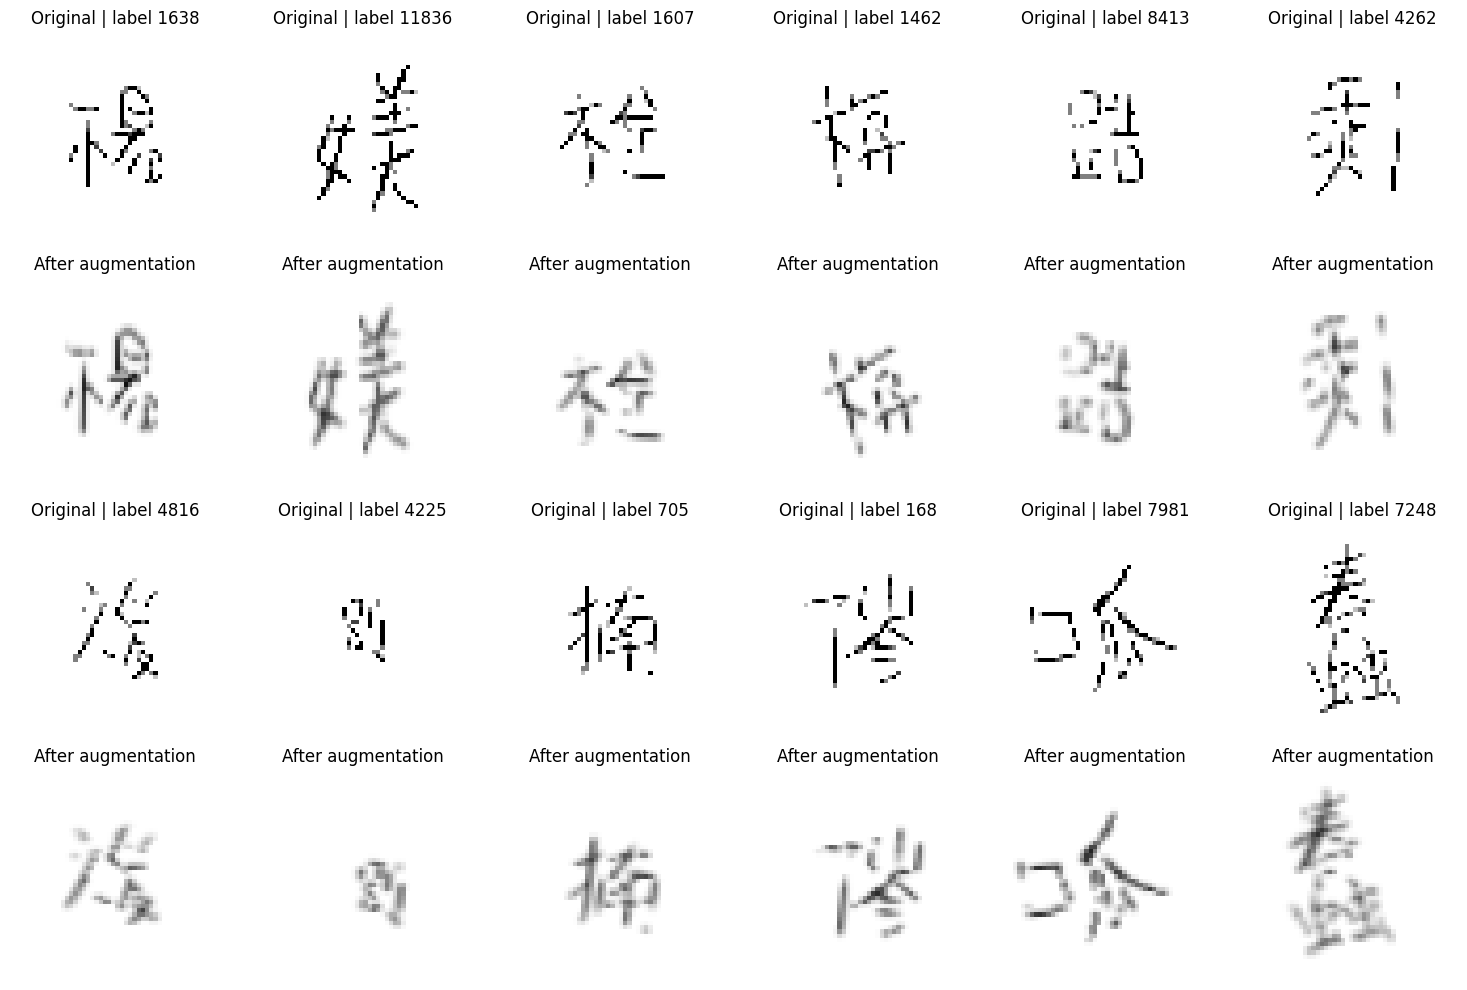

Inspection complete. No weights or files were changed.


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

print("=== Model architecture ===")
trial_model.summary()

print("\n=== Output layer ===")
output_layer = trial_model.layers[-1]
print("Name:", output_layer.name)
print("Compute dtype:", output_layer.compute_dtype)
print(
    "Activation:",
    getattr(getattr(output_layer, "activation", None), "__name__", None)
)

print("\n=== Augmentation settings ===")
try:
    augmentation = trial_model.get_layer("augmentation")
except ValueError:
    augmentation = None
    print("No top-level layer named 'augmentation' was found.")

if augmentation is not None:
    if hasattr(augmentation, "layers"):
        for layer in augmentation.layers:
            print("\nLayer:", layer.name)
            print(layer.get_config())
    else:
        print(augmentation.get_config())

print("\nReading one batch; the shuffle buffer may need to refill.",
      flush=True)

images, labels = next(iter(fixed_train_ds.take(1)))
preview_images = images[:12]
preview_labels = labels[:12].numpy().reshape(-1)

# This is a preview of augmentation only.
# No optimizer steps or model training are performed.
if augmentation is not None:
    augmented_images = augmentation(preview_images, training=True)
else:
    augmented_images = preview_images

fig, axes = plt.subplots(4, 6, figsize=(15, 10))

for i in range(12):
    row = (i // 6) * 2
    col = i % 6

    axes[row, col].imshow(
        preview_images[i].numpy().squeeze(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[row, col].set_title(f"Original | label {preview_labels[i]}")
    axes[row, col].axis("off")

    axes[row + 1, col].imshow(
        augmented_images[i].numpy().squeeze(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[row + 1, col].set_title("After augmentation")
    axes[row + 1, col].axis("off")

plt.tight_layout()
plt.show()

print("Inspection complete. No weights or files were changed.")

In [ ]:
import numpy as np
import tensorflow as tf

# Reuse the batch from the previous preview.
# No need to refill the full shuffle buffer.
required = ["trial_model", "images", "labels"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. "
        "Run the previous image-preview cell first."
    )

label_array = labels.numpy().reshape(-1)

# Take one image per label, up to 32 distinct labels.
_, first_indices = np.unique(label_array, return_index=True)
indices = np.sort(first_indices)[:32]

if len(indices) < 32:
    raise RuntimeError(
        "This batch has fewer than 32 distinct labels. "
        "Run the image-preview cell again to obtain another batch."
    )

tiny_x = tf.gather(images, indices)
tiny_y = tf.cast(tf.gather(labels, indices), tf.int32)
tiny_y = tf.reshape(tiny_y, [-1])

# Only the diagnostic model has augmentation/dropout removed.
def clone_for_diagnosis(layer):
    if (
        layer.name == "augmentation"
        or isinstance(layer, tf.keras.layers.Dropout)
    ):
        return tf.keras.layers.Activation(
            "linear", name=layer.name
        )
    return layer.__class__.from_config(layer.get_config())

tf.keras.utils.set_random_seed(123)

diagnostic_model = tf.keras.models.clone_model(
    trial_model,
    clone_function=clone_for_diagnosis
)

diagnostic_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ],
    jit_compile=False
)

# Each step uses the same 32 images.
tiny_ds = tf.data.Dataset.from_tensors(
    (tiny_x, tiny_y)
).repeat()

print("=== Tiny-set memorization test ===")
print("Images:", len(indices))
print("Distinct labels:", len(np.unique(tiny_y.numpy())))
print("Augmentation and Dropout: disabled in diagnostic model only")
print("Total optimizer steps: 300")
print("No files will be saved.", flush=True)

before = diagnostic_model.evaluate(
    tiny_x, tiny_y, batch_size=32,
    verbose=0, return_dict=True
)
print("Before training:", before, flush=True)

# Six reporting blocks, 50 updates each.
diagnostic_history = diagnostic_model.fit(
    tiny_ds,
    steps_per_epoch=50,
    epochs=6,
    callbacks=[tf.keras.callbacks.TerminateOnNaN()],
    verbose=2
)

after = diagnostic_model.evaluate(
    tiny_x, tiny_y, batch_size=32,
    verbose=0, return_dict=True
)

print("\n=== Tiny-set result ===")
print(f"Before loss: {before['loss']:.6f}")
print(f"Before accuracy: {before['accuracy']:.2%}")
print(f"After loss: {after['loss']:.6f}")
print(f"After accuracy: {after['accuracy']:.2%}")
print("This is accuracy on the SAME 32 training images.")
print("It is NOT validation or test accuracy.")
print("Original models and saved files were not changed.")

=== Tiny-set memorization test ===
Images: 32
Distinct labels: 32
Augmentation and Dropout: disabled in diagnostic model only
Total optimizer steps: 300
No files will be saved.
Before training: {'accuracy': 0.0, 'loss': 9.47964096069336}
Epoch 1/6
50/50 - 4s - 86ms/step - accuracy: 0.7837 - loss: 1.9193
Epoch 2/6
50/50 - 1s - 12ms/step - accuracy: 1.0000 - loss: 0.0065
Epoch 3/6
50/50 - 1s - 14ms/step - accuracy: 1.0000 - loss: 0.0026
Epoch 4/6
50/50 - 1s - 14ms/step - accuracy: 1.0000 - loss: 0.0015
Epoch 5/6
50/50 - 1s - 14ms/step - accuracy: 1.0000 - loss: 9.9349e-04
Epoch 6/6
50/50 - 1s - 14ms/step - accuracy: 1.0000 - loss: 7.3428e-04

=== Tiny-set result ===
Before loss: 9.479641
Before accuracy: 0.00%
After loss: 4.510776
After accuracy: 100.00%
This is accuracy on the SAME 32 training images.
It is NOT validation or test accuracy.
Original models and saved files were not changed.


In [ ]:
import tensorflow as tf

required = ["diagnostic_model", "tiny_x", "tiny_y"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Missing variables: {missing}")

# Independent copy; existing models are not modified.
bn_check_model = tf.keras.models.clone_model(diagnostic_model)
bn_check_model.set_weights(diagnostic_model.get_weights())

loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()

def measure(model):
    probabilities = model(tiny_x, training=False)
    loss = float(loss_fn(tiny_y, probabilities).numpy())

    predicted = tf.argmax(
        probabilities, axis=-1, output_type=tf.int32
    )
    accuracy = float(
        tf.reduce_mean(
            tf.cast(predicted == tiny_y, tf.float32)
        ).numpy()
    )
    return loss, accuracy

before_loss, before_accuracy = measure(bn_check_model)

# The diagnostic architecture has no augmentation or Dropout.
# No optimizer or gradient updates: only BN moving statistics update.
@tf.function
def update_bn_statistics(x):
    return bn_check_model(x, training=True)

print("Updating BN statistics on the diagnostic copy...", flush=True)

for _ in range(300):
    update_bn_statistics(tiny_x)

after_loss, after_accuracy = measure(bn_check_model)

print("\n=== BN comparison ===")
print(
    f"Before: loss={before_loss:.6f}, "
    f"accuracy={before_accuracy:.2%}"
)
print(
    f"After:  loss={after_loss:.6f}, "
    f"accuracy={after_accuracy:.2%}"
)
print("Only the diagnostic copy's BN statistics were updated.")
print("No files were saved. Existing models were not changed.")

Updating BN statistics on the diagnostic copy...

=== BN comparison ===
Before: loss=4.510776, accuracy=100.00%
After:  loss=0.016496, accuracy=100.00%
Only the diagnostic copy's BN statistics were updated.
No files were saved. Existing models were not changed.


In [ ]:
import math
import uuid
from pathlib import Path
from datetime import datetime, timezone
import tensorflow as tf

required = [
    "trial_model", "fixed_train_ds", "validation_ds",
    "TRAIN_EXAMPLES", "BATCH_SIZE"
]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Missing variables: {missing}")

if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("No GPU detected. Check runtime settings.")

drive_root = Path("/content/drive/MyDrive")
if not drive_root.is_dir():
    raise RuntimeError("Google Drive is not mounted.")

# A new folder: existing checkpoints are not overwritten.
stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
corrected_run_dir = (
    drive_root
    / "handwriting_project"
    / f"corrected_{stamp}_{uuid.uuid4().hex[:6]}"
)
corrected_run_dir.mkdir(parents=True, exist_ok=False)

expected_batches = math.ceil(TRAIN_EXAMPLES / BATCH_SIZE)

# Enforce the expected batch count.
# No steps_per_epoch: consume the entire finite dataset.
corrected_epoch_ds = fixed_train_ds.apply(
    tf.data.experimental.assert_cardinality(expected_batches)
)

callbacks = [
    tf.keras.callbacks.TerminateOnNaN(),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(corrected_run_dir / "recovery_model.keras"),
        save_freq=2000,
        save_best_only=False,
        verbose=0
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(corrected_run_dir / "best_model.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(corrected_run_dir / "training_log.csv")
    )
]

print("Continuing trial_model with its existing optimizer.", flush=True)
print("This model already completed the 1,000-batch trial.", flush=True)
print("Additional training batches:", expected_batches, flush=True)
print("Full validation dataset will be evaluated.", flush=True)
print("The test dataset will not be used.", flush=True)
print("Save directory:", corrected_run_dir, flush=True)
print("The shuffle buffer must refill before training.", flush=True)

corrected_history = trial_model.fit(
    corrected_epoch_ds,
    validation_data=validation_ds,
    epochs=1,
    callbacks=callbacks,
    verbose=1
)

trial_model.save(str(corrected_run_dir / "last_model.keras"))

print("\n=== Corrected full-pass result ===")
for name, values in corrected_history.history.items():
    print(f"{name}: {float(values[-1]):.6f}")

print("\nSaved to:", corrected_run_dir)
print("The original model and previous checkpoints were not changed.")

Continuing trial_model with its existing optimizer.
This model already completed the 1,000-batch trial.
Additional training batches: 20415
Full validation dataset will be evaluated.
The test dataset will not be used.
Save directory: /content/drive/MyDrive/handwriting_project/corrected_20261120_075922_4d6456
The shuffle buffer must refill before training.
20414/20415 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.0292 - loss: 7.8845 - top5_accuracy: 0.0742
Epoch 1: val_loss improved from None to 3.52819, saving model to /content/drive/MyDrive/handwriting_project/corrected_20261120_075922_4d6456/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/handwriting_project/corrected_20261120_075922_4d6456/best_model.keras
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 3197s 155ms/step - accuracy: 0.0964 - loss: 6.1376 - top5_accuracy: 0.2180 - val_accuracy: 0.2526 - val_loss: 3.5282 - val_top5_accuracy: 0.5305

=== Corrected full-pass result ===
accuracy: 0.096369
loss: 6.137554
top5